<a href="https://colab.research.google.com/github/shaistakhan7007-lang/Hotel-Booking/blob/main/ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
#import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("tensorflow version:", tf.__version__)


tensorflow version: 2.21.0


In [11]:
#load datasets
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("x_train images:", x_train.shape)
print("y_train labels:", y_train.shape)
print("x_test images:", x_test.shape)
print("y_test labels:", y_test.shape)

x_train images: (60000, 28, 28)
y_train labels: (60000,)
x_test images: (10000, 28, 28)
y_test labels: (10000,)


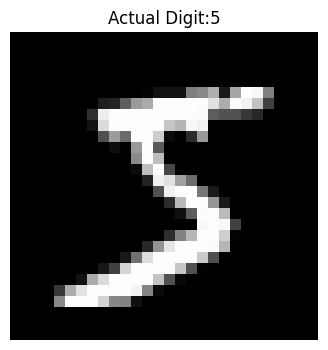

In [14]:
#display handwritten image
plt.figure(figsize=(4,4))

plt.imshow(x_train[0], cmap='gray')
plt.title(f"Actual Digit:{y_train[0]}")
plt.axis('off')
plt.show()

In [15]:
#normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [18]:
#build the ANN model
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
#compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [20]:
#train the model
history = model.fit(x_train, y_train, epochs=5, batch_size=32, validation_split=0.1 )

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9216 - loss: 0.2729 - val_accuracy: 0.9613 - val_loss: 0.1383
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9637 - loss: 0.1225 - val_accuracy: 0.9708 - val_loss: 0.1021
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9743 - loss: 0.0835 - val_accuracy: 0.9712 - val_loss: 0.0916
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9812 - loss: 0.0624 - val_accuracy: 0.9747 - val_loss: 0.0818
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9849 - loss: 0.0472 - val_accuracy: 0.9780 - val_loss: 0.0739


In [21]:
#evaluate the model
test_loss, test_acc = model.evaluate(x_test, y_test)
print("test loss:", test_loss)
print(f"Test accuracy: {test_acc * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9770 - loss: 0.0720
test loss: 0.07202953100204468
Test accuracy: 97.70%


In [24]:
#predict a handwritten image
predictions = model.predict(x_test[:5])

for i in range(5):
    predicted_digit = np.argmax(predictions[i])
    actual_digit = y_test[i]

    print("predicted",predicted_digit, " | actual",actual_digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
predicted 7  | actual 7
predicted 2  | actual 2
predicted 1  | actual 1
predicted 0  | actual 0
predicted 4  | actual 4


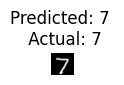

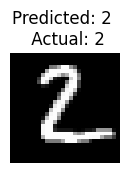

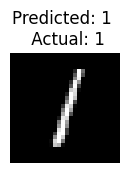

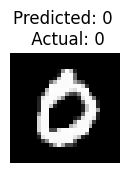

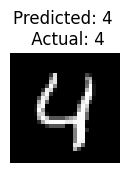

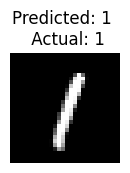

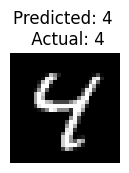

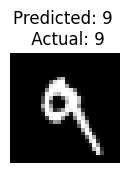

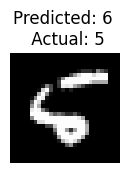

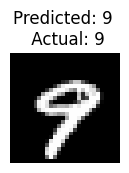

In [30]:
#display predictions
plt.figure(figsize=(2, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    prediction = model.predict(x_test[i:i+1], verbose=0 )

    predicted_digit = np.argmax(prediction)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Predicted: {predicted_digit} \n Actual: {y_test[i]}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()